<a href="https://colab.research.google.com/github/tovarrog24/Emergency-Department-Volume-and-Capacity/blob/main/learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import packages
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.metrics import r2_score

LOCAL_PATH = Path("../dataset/ED_Cleaned.csv")
REPO_URL = ("https://raw.githubusercontent.com/tovarrog24/"
            "Emergency-Department-Volume-and-Capacity/main/dataset/ED_Cleaned.csv")
source = LOCAL_PATH if LOCAL_PATH.exists() else REPO_URL

# Part 3 recodes these columns to 0/1 in place, so they are read as object (not str) dtype.
data = pd.read_csv(source, dtype={"TEACHINGDesignation": object,
                                  "MentalHealthShortageArea": object,
                                  "UrbanRuralDesi": object})
print("Loaded from:", source)
print("Shape:", data.shape)

Loaded from: https://raw.githubusercontent.com/tovarrog24/Emergency-Department-Volume-and-Capacity/main/dataset/ED_Cleaned.csv
Shape: (756, 19)


In [7]:
print(data["system"].unique())

['Alameda Health System' 'Sutter Health' 'No System'
 'Kaiser Foundation Hospitals' 'Dignity Health' 'John Muir Health'
 'Tenet Healthcare Corporation' 'Adventist Health Systems'
 'Providence St. Joseph Health' 'Alta Hospitals System'
 'Prime Healthcare Services' 'Avanti Hospitals' 'AHMC Healthcare, Inc.'
 'Cedars-Sinai Health System' 'MemorialCare' 'University of California'
 'Verity Health System' 'University of Southern California'
 'HCA Healthcare Corporation' 'County of Los Angeles'
 'Universal Health Services, Inc.' 'KPC Healthcare, Inc.'
 'Loma Linda University' 'Sharp Healthcare' 'Scripps Health'
 'Enloe Health' 'PIH Health' 'Emanate Health' 'Cottage Health'
 'Stanford Medicine' 'Kaweah Health' 'County of Ventura']


**Supervised Learning:** Try one or more of the supervised learning algorithms from K-nearest Neighbors, Naive Bayes, Support Vector Machine, and apply on the dataset, showing the effectiveness of the algorithm.

0.42290748898678415
[[ 4  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0
   0  0  0]
 [ 0  5  0  0  0  0  0  0  2  0  0  0  0  0  0  0  5  0  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [ 0  1  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [ 0  1  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  1  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [ 0  1  0  0  0  0  0  0 10  0  0  0  0  0  0  0  1  0  0  0  0  1  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  1  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  1  0  1  0  0  2  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0

Text(0, 0.5, 'LONGITUDE')

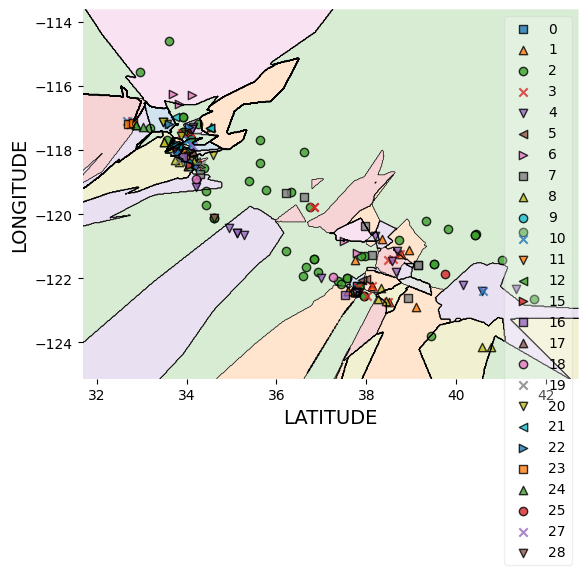

In [11]:
#Trying to use K-nearest Neighbors to classify certain data

#Some of the Specific Packages needed here
# Import needed packages for classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Import packages for visualization of results
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing
from mlxtend.plotting import plot_decision_regions

# Iport packages for evaluation
from sklearn.model_selection import train_test_split
from sklearn import metrics

import warnings
warnings.simplefilter("ignore")


#We will try to classify the system a hospital is in from the following two numerical features: ED_Burden; Bed_Size_Rank
systemClassifier = KNeighborsClassifier(n_neighbors = 5)

# Split data
X = data[["ED_Burden", "Bed_Size_Rank"]]
y = data[["system"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

# Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train model and make predictions for the test set.
systemClassifier.fit(X_train_scaled, np.ravel(y_train))
y_pred = systemClassifier.predict(scaler.transform(X_test))

# Predict one hospital
hos = pd.DataFrame(data={"ED_Burden": [400], "Bed_Size_Rank": [200]})
systemClassifier.predict(scaler.transform(hos))

# Compute metrics
print(metrics.accuracy_score(y_test, y_pred))
print(metrics.confusion_matrix(y_test, y_pred))

# Take a sample to keep runtime low while seeing what areas are classified as each hospital
systemSample = data.sample(200, random_state=123)
systemSample.describe()

# Create integer-valued labels for plot_decision_regions()
systemSample["Int"] = systemSample["system"].replace(
    to_replace=['Alameda Health System', 'Sutter Health', 'No System'
 'Kaiser Foundation Hospitals', 'Dignity Health', 'John Muir Health',
 'Tenet Healthcare Corporation', 'Adventist Health Systems',
 'Providence St. Joseph Health', 'Alta Hospitals System',
 'Prime Healthcare Services', 'Avanti Hospitals', 'AHMC Healthcare, Inc.',
 'Cedars-Sinai Health System', 'MemorialCare', 'University of California',
 'Verity Health System', 'University of Southern California',
 'HCA Healthcare Corporation', 'County of Los Angeles',
 'Universal Health Services, Inc.', 'KPC Healthcare, Inc.',
 'Loma Linda University', 'Sharp Healthcare', 'Scripps Health',
 'Enloe Health', 'PIH Health', 'Emanate Health', 'Cottage Health',
 'Stanford Medicine', 'Kaweah Health', 'County of Ventura'],
    value=[int(0), int(1), int(2), int(3), int(4), int(5), int(6), int(7), int(8), int(9), int(10), int(11), int(12), int(13),
           int(14), int(15), int(16), int(17), int(18), int(19), int(20), int(21), int(22), int(23), int(24), int(25), int(26),
           int(27), int(28), int(29), int(30), int(31)],
)

# Define input and output features
X = systemSample[["ED_Burden", "Bed_Size_Rank"]]
y = systemSample[["Int"]]

# Fit model
systemClassifier.fit(X, np.ravel(y))

# Set background opacity to 20%
contourf_kwargs = {"alpha": 0.2}

# Plot decision boundary regions
p = plot_decision_regions(
    X.to_numpy(), np.ravel(y), clf=systemClassifier, contourf_kwargs=contourf_kwargs
)

# Add title and axis labels
p.set_xlabel("ED_Burden", fontsize=14)
p.set_ylabel("Bed_Size_Rank", fontsize=14)


0.3392070484581498
[[ 1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  2  0
   0  0  0]
 [ 0  6  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  1  0  0  0  0  1  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  1  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  2  0  0  2  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  2  0  0  1  0  0  0  0  0  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0
   0  0  0]
 [ 0  3  0  0  0  0  0  0  0  7  0  0  0  0  0  0  0  3  1  0  0  0  3  0
   0  0  0]
 [ 0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   1  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0 

Text(0, 0.5, 'EDStations')

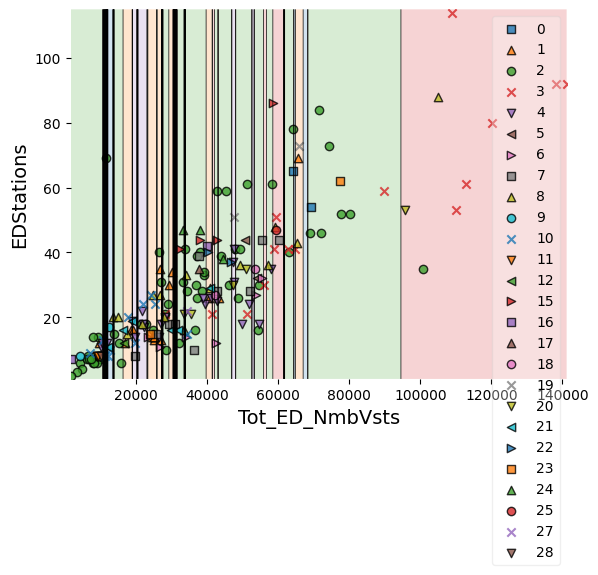

In [12]:
#Trying to use K-nearest Neighbors to classify certain data

#We will try to classify the system a hospital is in from the following two numerical features: LATITUDE, LONGITUDE (geographically essentially)
systemClassifier = KNeighborsClassifier(n_neighbors = 5)

# Split data
X = data[["Tot_ED_NmbVsts", "EDStations"]]
y = data[["system"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

# Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train model and make predictions for the test set.
systemClassifier.fit(X_train_scaled, np.ravel(y_train))
y_pred = systemClassifier.predict(scaler.transform(X_test))

# Predict one hospital
hos = pd.DataFrame(data={"Tot_ED_NmbVsts": [400], "EDStations": [200]})
systemClassifier.predict(scaler.transform(hos))

# Compute metrics
print(metrics.accuracy_score(y_test, y_pred))
print(metrics.confusion_matrix(y_test, y_pred))

# Take a sample to keep runtime low while seeing what areas are classified as each hospital
systemSample = data.sample(200, random_state=123)
systemSample.describe()

# Create integer-valued labels for plot_decision_regions()
systemSample["Int"] = systemSample["system"].replace(
    to_replace=['Alameda Health System', 'Sutter Health', 'No System',
 'Kaiser Foundation Hospitals', 'Dignity Health', 'John Muir Health',
 'Tenet Healthcare Corporation', 'Adventist Health Systems',
 'Providence St. Joseph Health', 'Alta Hospitals System',
 'Prime Healthcare Services', 'Avanti Hospitals', 'AHMC Healthcare, Inc.',
 'Cedars-Sinai Health System', 'MemorialCare', 'University of California',
 'Verity Health System', 'University of Southern California',
 'HCA Healthcare Corporation', 'County of Los Angeles',
 'Universal Health Services, Inc.', 'KPC Healthcare, Inc.',
 'Loma Linda University', 'Sharp Healthcare', 'Scripps Health',
 'Enloe Health', 'PIH Health', 'Emanate Health', 'Cottage Health',
 'Stanford Medicine', 'Kaweah Health', 'County of Ventura'],
    value=[int(0), int(1), int(2), int(3), int(4), int(5), int(6), int(7), int(8), int(9), int(10), int(11), int(12), int(13),
           int(14), int(15), int(16), int(17), int(18), int(19), int(20), int(21), int(22), int(23), int(24), int(25), int(26),
           int(27), int(28), int(29), int(30), int(31)],
)

# Define input and output features
X = systemSample[["Tot_ED_NmbVsts", "EDStations"]]
y = systemSample[["Int"]]

# Fit model
systemClassifier.fit(X, np.ravel(y))

# Set background opacity to 20%
contourf_kwargs = {"alpha": 0.2}

# Plot decision boundary regions
p = plot_decision_regions(
    X.to_numpy(), np.ravel(y), clf=systemClassifier, contourf_kwargs=contourf_kwargs
)

# Add title and axis labels
p.set_xlabel("Tot_ED_NmbVsts", fontsize=14)
p.set_ylabel("EDStations", fontsize=14)


0.6343612334801763
[[107  35]
 [ 48  37]]


Text(0, 0.5, 'EDStations')

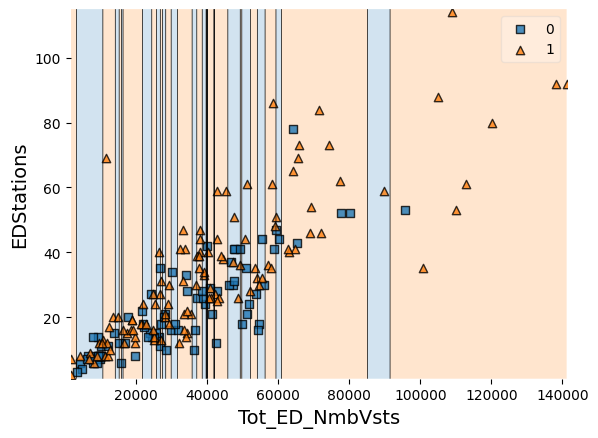

In [13]:
#Trying to use K-nearest Neighbors to classify certain data

#We will try to classify the system a hospital is in from the following two numerical features: LATITUDE, LONGITUDE (geographically essentially)
systemClassifier = KNeighborsClassifier(n_neighbors = 5)

# Split data
X = data[["Tot_ED_NmbVsts", "EDStations"]]
y = data[["MentalHealthShortageArea"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

# Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train model and make predictions for the test set.
systemClassifier.fit(X_train_scaled, np.ravel(y_train))
y_pred = systemClassifier.predict(scaler.transform(X_test))

# Predict one hospital
hos = pd.DataFrame(data={"Tot_ED_NmbVsts": [400], "EDStations": [200]})
systemClassifier.predict(scaler.transform(hos))

# Compute metrics
print(metrics.accuracy_score(y_test, y_pred))
print(metrics.confusion_matrix(y_test, y_pred))

# Take a sample to keep runtime low while seeing what areas are classified as each hospital
systemSample = data.sample(200, random_state=123)
systemSample.describe()

# Create integer-valued labels for plot_decision_regions()
systemSample["Int"] = systemSample["MentalHealthShortageArea"].replace(
    to_replace=["Yes", "No"],
    value=[int(0), int(1)],
)

# Define input and output features
X = systemSample[["Tot_ED_NmbVsts", "EDStations"]]
y = systemSample[["Int"]]

# Fit model
systemClassifier.fit(X, np.ravel(y))

# Set background opacity to 20%
contourf_kwargs = {"alpha": 0.2}

# Plot decision boundary regions
p = plot_decision_regions(
    X.to_numpy(), np.ravel(y), clf=systemClassifier, contourf_kwargs=contourf_kwargs
)

# Add title and axis labels
p.set_xlabel("Tot_ED_NmbVsts", fontsize=14)
p.set_ylabel("EDStations", fontsize=14)


This just tells us that the features e tried to predict are not clustered in all the data. Perhaps if we partitioned the data into a seperate dataset that only contained the urbal hospitals or the rural hospitals it could yeild better insight. Of the three times we tried using K-nearest neigbors, comparing the system geographically seemed to work out the best.

In [3]:
#Trying to use a Support Vector Machine

**Unsupervised Learning:** Try one or more of the unsupervised learning algorithms from K-means Clustering or Hierachical Clustering, and apply on the dataset, showing the effectiveness of the algorithm.

In [4]:
#Trying to use K-Means Clustering

In [5]:
#Trying to use Hierachical Clustering